### Human Stress Detection - 추가 분석 : 너무 좋은 성능 의심하기
### 학습 내용
 * 기본 분석([01_07_Human_Stress_Detection](https://ldjwj.github.io/dataAnalysis/01_07_Human_Stress_Detection.html))에서 나온 **테스트 정확도 100%**가 왜 나왔는지 따져 보기
 * 상관관계, 변수 하나만 쓴 모델, 그룹별 값의 범위, 중복/유사 행, 값의 분포로 **합성(인공) 데이터의 특징** 찾기
 * 성능이 "너무 좋을 때" 확인해야 할 **체크리스트** 만들기

### 내용
 * 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 1. 데이터 준비
 * 2. 변수 간 상관관계
 * 3. 변수 하나만 써도 맞힐 수 있을까?
 * 4. 스트레스 수준별 값의 범위 - 겹치는 구간이 있을까?
 * 5. 중복 행과 거의 같은 행
 * 6. 합성 데이터의 흔적 - 값이 일정한 간격의 직선 위에 있다
 * 7. 교차검증과 간단한 실험 (라벨 섞기, 잡음 추가)
 * 8. 결론 - 왜 100%가 나왔을까? / 실제 데이터라면 의심할 체크리스트
 * 9. 정리

### 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 기본 분석에서는 `sr`(코골이 범위), `bo`(혈중 산소), `sr.1`(수면 시간) 3개 변수로 스트레스 수준(0~4, 5단계)을 예측했다.
   * KNN : 학습 1.0 / **테스트 1.0 (100%)**
   * DecisionTree(max_depth=3), RandomForest(max_depth=3) : 학습 1.0 / 테스트 0.992
 * 변수를 `sr.1`(수면 시간) **1개로 줄여도** 테스트 정확도 0.992 그대로였다.
 * 5단계 분류에서 변수 1개로 99%는 현실에서 거의 일어나기 어렵다. **"모델이 좋다"가 아니라 "데이터가 이상하다"**는 신호일 수 있다.
 * 또한 평가는 train_test_split **1번**만 했다. 이번에는 여러 각도에서 데이터 자체를 점검한다.

### 필수 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# 한글 폰트 설정
# - koreanize-matplotlib이 설치되어 있으면 OS와 상관없이 나눔고딕을 사용 (pip install koreanize-matplotlib)
# - 없으면 OS에 맞는 기본 한글 폰트를 사용
try:
    import koreanize_matplotlib
except ImportError:
    import platform
    plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic',
                                   'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])

### 1. 데이터 준비
 * 원본 CSV는 컬럼명 `sr`이 두 번 나온다(코골이 범위, 수면 시간). pandas가 두 번째를 `sr.1`로 바꿔 읽는다.
 * 이해하기 쉽게 한글 이름으로 바꾼다.

In [2]:
dat = pd.read_csv("./data/HumanStress/SaYoPillow.csv")
print(dat.shape)

name_map = {'sr': '코골이', 'rr': '호흡수', 't': '체온', 'lm': '사지움직임',
            'bo': '혈중산소', 'rem': '안구운동', 'sr.1': '수면시간', 'hr': '심박수', 'sl': '스트레스'}
df = dat.rename(columns=name_map)
features = [c for c in df.columns if c != '스트레스']

df.head()

(630, 9)


,코골이,호흡수,체온,사지움직임,혈중산소,안구운동,수면시간,심박수,스트레스
0,93.80,25.680,91.840,16.600,89.840,99.60,1.840,74.20,3
1,91.64,25.104,91.552,15.880,89.552,98.88,1.552,72.76,3
2,60.00,20.000,96.000,10.000,95.000,85.00,7.000,60.00,1
3,85.76,23.536,90.768,13.920,88.768,96.92,0.768,68.84,3
4,48.12,17.248,97.872,6.496,96.248,72.48,8.248,53.12,0


In [3]:
# 스트레스 수준별 행 수
df['스트레스'].value_counts().sort_index()

스트레스
0    126
1    126
2    126
3    126
4    126
Name: count, dtype: int64

* 한줄 확인 : 630행, 입력 변수 8개. 스트레스 0~4 수준이 **모두 정확히 126개**씩이다.
  * 실제로 수집한 데이터에서 다섯 그룹의 인원이 1명도 다르지 않게 똑같은 경우는 드물다. 첫 번째 의심 신호.

### 2. 변수 간 상관관계

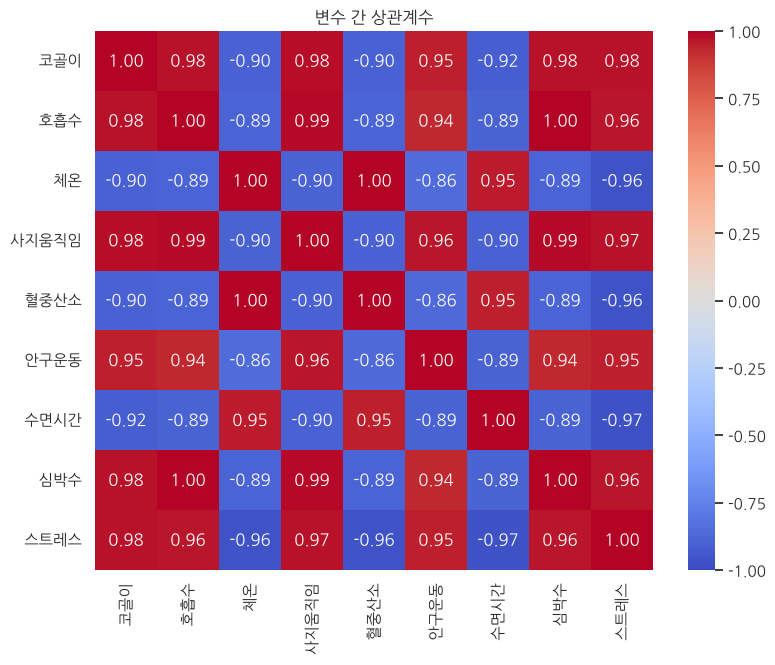

In [4]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('변수 간 상관계수')
plt.show()

In [5]:
# 각 변수와 스트레스 수준의 상관계수 (절댓값 기준 정렬)
corr['스트레스'].drop('스트레스').sort_values(key=abs, ascending=False).round(3)

코골이      0.975
수면시간    -0.973
사지움직임    0.971
심박수      0.964
호흡수      0.964
체온      -0.962
혈중산소    -0.961
안구운동     0.952
Name: 스트레스, dtype: float64

In [6]:
# 입력 변수끼리의 상관계수 절댓값 중 가장 작은 값
upper = corr.loc[features, features].abs().where(np.triu(np.ones((8, 8)), k=1).astype(bool))
print('입력 변수끼리 상관계수 절댓값 최소 :', round(upper.min().min(), 3))
print('호흡수-심박수 상관계수 :', round(corr.loc['호흡수', '심박수'], 4))

입력 변수끼리 상관계수 절댓값 최소 : 0.857
호흡수-심박수 상관계수 : 1.0


* 한줄 확인 : 모든 입력 변수가 스트레스와 **절댓값 0.95 이상**의 상관을 보인다(가장 높은 코골이 0.975, 가장 낮은 안구운동 0.952).
  * 입력 변수끼리도 상관계수 절댓값이 **최소 0.857**이고, 호흡수-심박수는 **1.000**, 체온-혈중산소는 **0.998**(히트맵 1.00)로 사실상 같은 변수다.
  * 사람의 생체 신호 8가지가 이렇게 한 몸처럼 움직이는 것은 매우 부자연스럽다.

### 3. 변수 하나만 써도 맞힐 수 있을까?
 * 각 변수를 **하나씩만** 넣고 5겹 교차검증(StratifiedKFold) 정확도를 계산한다.
 * 5단계 분류이므로 아무렇게나 찍으면 정확도는 약 **0.2(20%)**이다.

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y = df['스트레스']

rows = []
for col in features:
    scores = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=42),
                             df[[col]], y, cv=skf)
    rows.append({'변수': col, '평균 정확도': scores.mean(), '최소': scores.min()})

one_var = pd.DataFrame(rows).sort_values('평균 정확도', ascending=False).round(3)
one_var

,변수,평균 정확도,최소
0,코골이,0.990,0.976
1,호흡수,0.986,0.968
2,체온,0.986,0.960
3,사지움직임,0.984,0.960
4,혈중산소,0.984,0.968
5,안구운동,0.984,0.960
7,심박수,0.984,0.960
6,수면시간,0.981,0.944


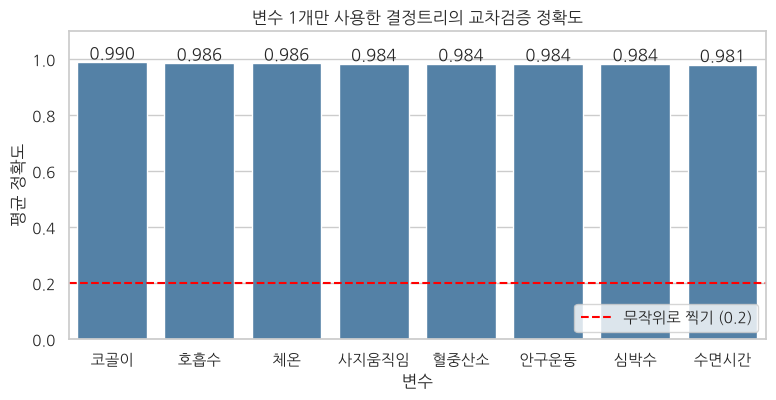

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=one_var, x='변수', y='평균 정확도', color='steelblue', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.3f')
ax.axhline(0.2, color='red', ls='--', label='무작위로 찍기 (0.2)')
ax.set_ylim(0, 1.1)
ax.set_title('변수 1개만 사용한 결정트리의 교차검증 정확도')
ax.legend(loc='lower right')
plt.show()

* 한줄 확인 : 변수 **하나만** 써도 8개 중 **모든 변수가 교차검증 정확도 0.98 이상**(코골이 0.990 ~ 수면시간 0.981)이다. 무작위 찍기(0.2)의 약 5배.
  * 어떤 변수 하나로도 거의 완벽하게 맞힌다는 것은, 각 변수 안에 정답(스트레스 수준)이 이미 "구간"으로 새겨져 있다는 뜻이다.

### 4. 스트레스 수준별 값의 범위 - 겹치는 구간이 있을까?
 * 실제 데이터라면 스트레스가 높은 사람과 낮은 사람의 값이 **어느 정도 겹치는 것**이 자연스럽다.

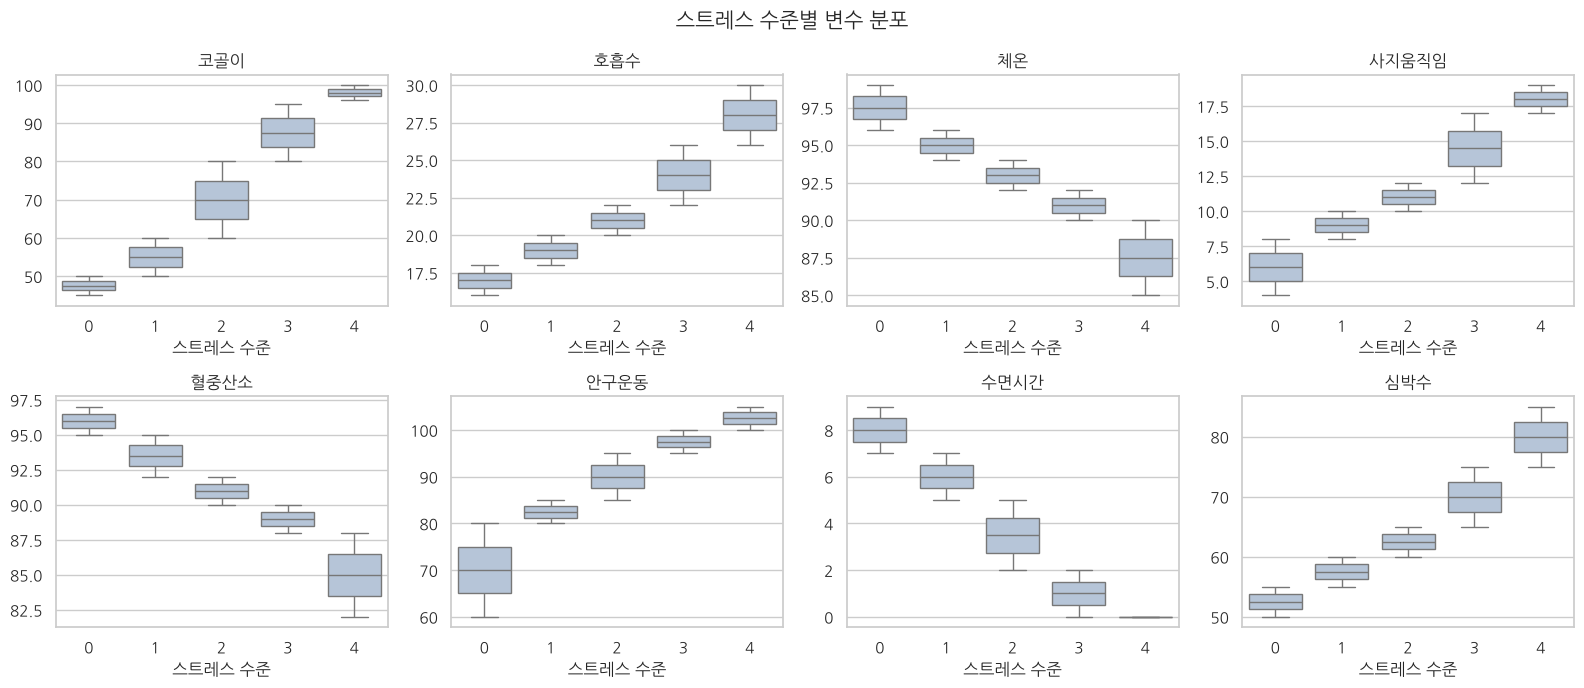

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x='스트레스', y=col, ax=ax, color='lightsteelblue')
    ax.set_title(col)
    ax.set_xlabel('스트레스 수준')
    ax.set_ylabel('')
plt.suptitle('스트레스 수준별 변수 분포', fontsize=15)
plt.tight_layout()
plt.show()

In [10]:
# 스트레스 수준별 최솟값 ~ 최댓값
rng = df.groupby('스트레스')[features].agg(['min', 'max'])
range_table = pd.DataFrame({col: [f"{rng.loc[s, (col, 'min')]:g} ~ {rng.loc[s, (col, 'max')]:g}"
                                  for s in rng.index] for col in features}, index=rng.index)
range_table

,코골이,호흡수,체온,사지움직임,혈중산소,안구운동,수면시간,심박수
스트레스,,,,,,,,
0,45 ~ 50,16 ~ 18,96 ~ 99,4 ~ 8,95 ~ 97,60 ~ 80,7 ~ 9,50 ~ 55
1,50 ~ 60,18 ~ 20,94 ~ 96,8 ~ 10,92 ~ 95,80 ~ 85,5 ~ 7,55 ~ 60
2,60 ~ 80,20 ~ 22,92 ~ 94,10 ~ 12,90 ~ 92,85 ~ 95,2 ~ 5,60 ~ 65
3,80 ~ 95,22 ~ 26,90 ~ 92,12 ~ 17,88 ~ 90,95 ~ 100,0 ~ 2,65 ~ 75
4,96 ~ 100,26 ~ 30,85 ~ 90,17 ~ 19,82 ~ 88,100 ~ 105,0 ~ 0,75 ~ 85


In [11]:
# 이웃한 수준끼리 범위가 겹치는 "폭" 계산 (0이면 경계값 한 점에서만 맞닿음)
rows = []
for col in features:
    for s in range(4):
        a_min, a_max = rng.loc[s, (col, 'min')], rng.loc[s, (col, 'max')]
        b_min, b_max = rng.loc[s + 1, (col, 'min')], rng.loc[s + 1, (col, 'max')]
        overlap = max(0, min(a_max, b_max) - max(a_min, b_min))
        rows.append({'변수': col, '비교': f'{s} vs {s+1}', '겹치는 폭': overlap})
ov = pd.DataFrame(rows)
print('겹치는 폭이 0보다 큰 경우 :', (ov['겹치는 폭'] > 0).sum(), '/', len(ov))
ov.pivot(index='변수', columns='비교', values='겹치는 폭')

겹치는 폭이 0보다 큰 경우 : 0 / 32


비교,0 vs 1,1 vs 2,2 vs 3,3 vs 4
변수,,,,
사지움직임,0,0,0,0
수면시간,0,0,0,0
심박수,0,0,0,0
안구운동,0,0,0,0
체온,0,0,0,0
코골이,0,0,0,0
혈중산소,0,0,0,0
호흡수,0,0,0,0


* 한줄 확인 : 박스플롯이 계단처럼 **서로 완전히 분리**되어 있다. 이웃한 수준끼리 범위를 비교한 32개 경우 모두 **겹치는 폭이 0**이다. 경계값 한 점(예: 코골이 50은 0단계의 최댓값이면서 1단계의 최솟값)만 공유한다.
  * 단독 변수 모델이 1.0이 아니라 0.98~0.99인 것은 이 **경계값에 놓인 몇몇 행** 때문이다.
  * 예) 코골이 : 0단계 45~50, 1단계 50~60, 2단계 60~80, 3단계 80~95, 4단계 96~100 → 값만 보면 수준이 바로 결정된다.
  * 수면시간은 3단계(0~2)와 4단계(0)가 0에서 겹쳐 있어, 변수 1개 모델에서 수면시간이 가장 낮은 정확도를 보인 이유가 된다.

### 5. 중복 행과 거의 같은 행
 * 같은 데이터가 학습/테스트에 함께 들어가면 "외운 답"으로 점수가 올라간다. 중복 행부터 확인한다.

In [12]:
print('완전히 같은 행 :', df.duplicated().sum())
print('소수점 반올림(정수) 후 같은 행 :', df.round(0).duplicated().sum())

완전히 같은 행 : 0
소수점 반올림(정수) 후 같은 행 : 490


In [13]:
# 표준화 후 가장 가까운 이웃까지의 거리
Z = StandardScaler().fit_transform(df[features])
dist, idx = NearestNeighbors(n_neighbors=2).fit(Z).kneighbors(Z)
nn_dist = dist[:, 1]
same_label = (y.values[idx[:, 1]] == y.values).mean()

print('가장 가까운 이웃까지 거리 - 최소 %.4f / 중앙값 %.4f / 최대 %.4f' % (nn_dist.min(), np.median(nn_dist), nn_dist.max()))
print('가장 가까운 이웃의 스트레스 수준이 같은 비율 : %.3f' % same_label)

가장 가까운 이웃까지 거리 - 최소 0.0127 / 중앙값 0.0182 / 최대 0.0209
가장 가까운 이웃의 스트레스 수준이 같은 비율 : 1.000


* 한줄 확인 : 완전히 같은 행은 0개지만, 정수로 반올림하면 **490개(78%)**가 다른 행과 같아진다. 값만 소수점 아래로 조금씩 다른 "거의 같은 행"이 대부분이다.
  * 모든 행이 표준화 거리 0.013~0.021 안에 "쌍둥이 같은 이웃"을 가지고, 그 이웃의 스트레스 수준이 같은 비율이 **1.000(100%)** → KNN이 100%를 낸 이유다.

### 6. 합성 데이터의 흔적 - 값이 일정한 간격의 직선 위에 있다
 * 두 변수의 산점도를 그려 보면 데이터가 어떻게 만들어졌는지 보인다.

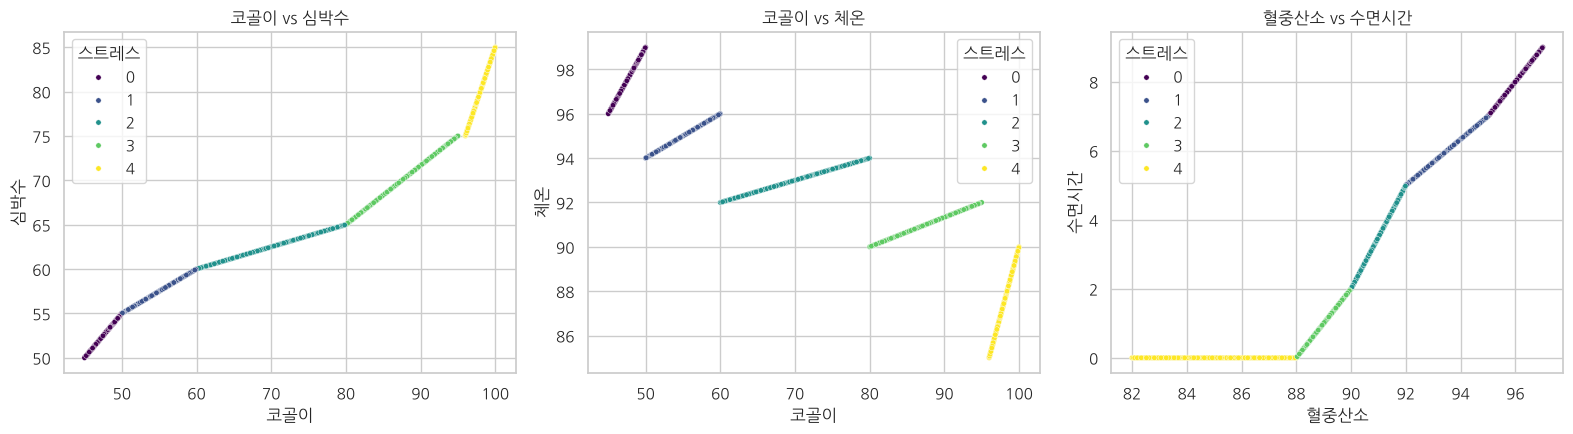

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
pairs = [('코골이', '심박수'), ('코골이', '체온'), ('혈중산소', '수면시간')]
for ax, (a, b) in zip(axes, pairs):
    sns.scatterplot(data=df, x=a, y=b, hue='스트레스', palette='viridis', s=15, ax=ax)
    ax.set_title(f'{a} vs {b}')
plt.tight_layout()
plt.show()

* 한줄 확인 : 점들이 흩어진 구름이 아니라 **스트레스 수준마다 하나의 짧은 직선(선분)** 위에 놓여 있다.

In [15]:
# 같은 스트레스 수준 안에서 변수끼리의 상관계수 절댓값 최소
for s, g in df.groupby('스트레스'):
    c = g[features].drop(columns='수면시간' if s == 4 else []).corr().abs()
    print(f'스트레스 {s} : 그룹 안 상관계수 절댓값 최소 = {c.values.min():.4f}')
print('스트레스 4의 수면시간 고유값 :', df.loc[df['스트레스'] == 4, '수면시간'].unique())

스트레스 0 : 그룹 안 상관계수 절댓값 최소 = 1.0000
스트레스 1 : 그룹 안 상관계수 절댓값 최소 = 1.0000
스트레스 2 : 그룹 안 상관계수 절댓값 최소 = 1.0000
스트레스 3 : 그룹 안 상관계수 절댓값 최소 = 1.0000
스트레스 4 : 그룹 안 상관계수 절댓값 최소 = 1.0000
스트레스 4의 수면시간 고유값 : [0.]


In [16]:
# 같은 수준 안에서 코골이 값을 정렬했을 때 이웃한 값의 간격
for s, g in df.groupby('스트레스'):
    gap = np.diff(np.sort(g['코골이'].values)).round(4)
    print(f'스트레스 {s} : 간격 종류 {np.unique(gap)}')

스트레스 0 : 간격 종류 [0.04]
스트레스 1 : 간격 종류 [0.08]
스트레스 2 : 간격 종류 [0.16]
스트레스 3 : 간격 종류 [0.12]
스트레스 4 : 간격 종류 [0.032]


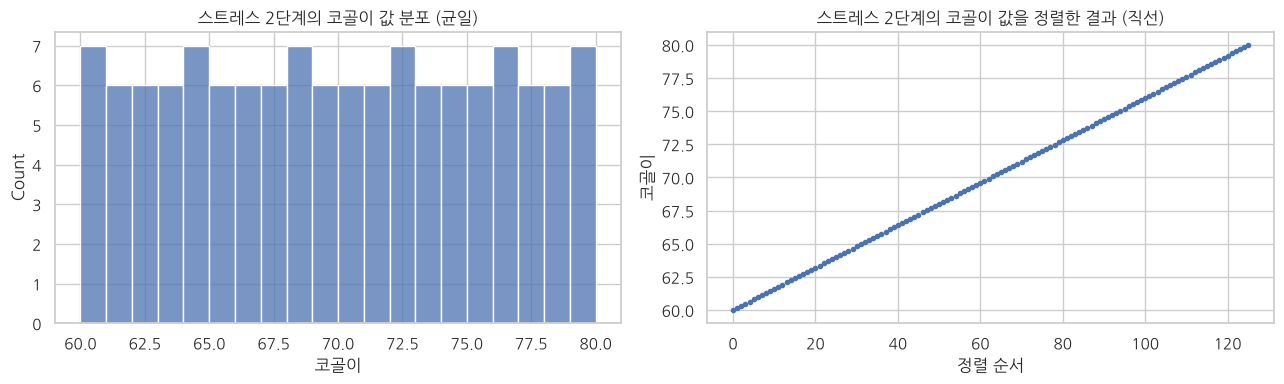

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[df['스트레스'] == 2]['코골이'], bins=20, ax=axes[0])
axes[0].set_title('스트레스 2단계의 코골이 값 분포 (균일)')
g2 = df[df['스트레스'] == 2].sort_values('코골이')
axes[1].plot(range(len(g2)), g2['코골이'].values, marker='.', ls='')
axes[1].set_title('스트레스 2단계의 코골이 값을 정렬한 결과 (직선)')
axes[1].set_xlabel('정렬 순서')
axes[1].set_ylabel('코골이')
plt.tight_layout()
plt.show()

* 한줄 확인 : 같은 스트레스 수준 안에서는 8개 변수의 상관계수 절댓값이 **모두 1.0000**(완벽한 직선 관계)이다. (4단계의 수면시간은 모두 0이라 계산에서 제외)
  * 값을 정렬하면 이웃한 값의 간격이 수준마다 **딱 한 종류**(0단계 0.04, 1단계 0.08, 2단계 0.16, 3단계 0.12, 4단계 0.032)로 일정하다. 즉 **등간격**. 히스토그램은 평평(균일)하고, 정렬한 값은 완벽한 직선이다.
  * 즉 이 데이터는 **"수준별 최솟값 ~ 최댓값 구간을 126등분한 값"**을 8개 변수에 똑같이 적용해 만든 **합성 데이터**로 보인다.

### 7. 교차검증과 간단한 실험
#### 7-1. 전체 변수, 여러 모델의 5겹 교차검증

In [18]:
X = df[features]
models = {
    'LogisticRegression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'DecisionTree(depth=3)': DecisionTreeClassifier(max_depth=3, random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2),
}
cv_rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=skf)
    cv_rows.append({'모델': name, '평균': s.mean(), '표준편차': s.std(), '최소': s.min(), '각 fold': np.round(s, 3)})
pd.DataFrame(cv_rows).round(4)

,모델,평균,표준편차,최소,각 fold
0,LogisticRegression,1.0000,0.0000,1.0000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
1,KNN,1.0000,0.0000,1.0000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
2,DecisionTree(depth=3),0.8238,0.0884,0.7698,"[0.77, 1.0, 0.778, 0.794, 0.778]"
3,RandomForest,0.9905,0.0093,0.9762,"[0.976, 1.0, 1.0, 0.992, 0.984]"


* 한줄 확인 : LogisticRegression과 KNN은 5개 fold 모두 **1.0**, RandomForest는 평균 **0.9905**(0.976~1.0)이다.
  * DecisionTree(depth=3)만 평균 0.824로 낮고 fold에 따라 0.77~1.0으로 흔들리는데, 질문을 3번으로 제한한 **깊이 제한** 때문이다. (3절처럼 깊이 4면 변수 1개로도 0.98 이상)
  * 교차검증으로 평가해도 결과가 같다. 즉 "분할 운"이 좋았던 것이 아니라 **데이터 자체가 쉽게 만들어져 있다**.

#### 7-2. 라벨 섞기 실험 (정답을 무작위로 섞으면?)
 * 정답을 섞었는데도 점수가 높게 나오면 코드에 누수가 있다는 뜻이다. 이 경우 0.2 근처가 나와야 정상이다.

In [19]:
rng_np = np.random.RandomState(42)
y_shuffled = rng_np.permutation(y.values)
s = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2), X, y_shuffled, cv=skf)
print('라벨을 섞은 뒤 RandomForest 정확도 : %.3f' % s.mean())

라벨을 섞은 뒤 RandomForest 정확도 : 0.230


* 한줄 확인 : 라벨을 섞으면 정확도가 **0.230**으로 무작위 수준(0.2)까지 떨어진다. 코드(평가 과정)에는 누수가 없고, 높은 점수는 데이터에서 나온 것이다.

#### 7-3. 잡음 추가 실험 (실제 측정처럼 오차가 있다면?)
 * 실제 센서 값에는 측정 오차가 있다. 각 변수의 표준편차에 비례하는 정규분포 잡음을 더해 정확도가 어떻게 변하는지 본다.

In [20]:
noise_rows = []
for level in [0, 0.1, 0.3, 0.5, 1.0]:
    noise = np.random.RandomState(42).normal(0, 1, X.shape) * X.std().values * level
    Xn = X + noise
    for name in ['LogisticRegression', 'RandomForest']:
        s = cross_val_score(models[name], Xn, y, cv=skf)
        noise_rows.append({'잡음 크기(표준편차 배)': level, '모델': name, '정확도': s.mean()})
noise_df = pd.DataFrame(noise_rows)
noise_df.pivot(index='잡음 크기(표준편차 배)', columns='모델', values='정확도').round(3)

모델,LogisticRegression,RandomForest
잡음 크기(표준편차 배),,
0.0,1.000,0.990
0.1,1.000,1.000
0.3,1.000,0.995
0.5,0.951,0.938
1.0,0.705,0.657


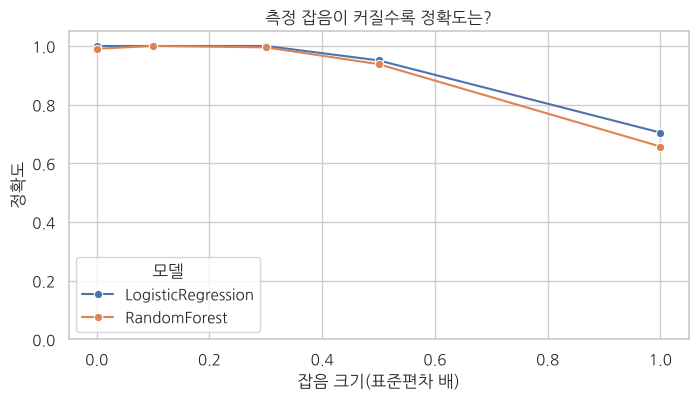

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=noise_df, x='잡음 크기(표준편차 배)', y='정확도', hue='모델', marker='o', ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title('측정 잡음이 커질수록 정확도는?')
plt.show()

* 한줄 확인 : 표준편차의 0.3배 잡음까지는 정확도 0.995 이상을 유지하지만, 0.5배에서 0.951 / 0.938, **1.0배에서 0.705(LogisticRegression) / 0.657(RandomForest)**로 떨어진다.
  * 실제 데이터의 정확도는 데이터의 "잡음 수준"에 크게 좌우된다. 합성 데이터의 100%를 실제 환경 성능으로 기대하면 안 된다.

### 8. 결론
#### 왜 100%가 나왔을까?
 1. **구간으로 만들어진 데이터** : 모든 변수가 스트레스 수준마다 겹치지 않는 구간(경계값 한 점만 공유)에 들어 있다. → 변수 1개로도 구간만 알면 답이 정해진다.
 2. **한 줄 위의 점들** : 같은 수준 안에서 8개 변수가 완벽한 직선 관계(상관계수 ±1)이고, 값이 일정한 간격으로 배치되어 있다. → 사실상 정보가 "수준 + 위치(0~1)" 2개뿐이다.
 3. **촘촘한 이웃** : 모든 행 바로 옆에 같은 수준의 이웃이 있다. → KNN, 결정트리 모두 쉽게 100% 가까이 맞힌다.
 4. 평가 방법(라벨 섞기, 교차검증)에는 문제가 없었다. **모델이 뛰어난 것이 아니라 문제가 쉬운 것**이다.

#### 실제 데이터에서 성능이 "너무 좋을 때" 확인할 체크리스트
| 확인 항목 | 확인 방법 | 이 데이터 결과 |
|---|---|---|
| 그룹 인원이 비현실적으로 똑같은가? | `value_counts()` | 5개 수준 모두 126개 |
| 변수 하나로 거의 다 맞히는가? (정답 누수 의심) | 변수별 단독 모델 정확도 | 8개 변수 모두 0.98 이상 |
| 그룹별 값 범위가 겹치지 않는가? | 박스플롯, 그룹별 min/max | 겹치는 폭 0 (경계값만 공유) |
| 변수끼리 상관이 1에 가까운가? (같은 정보 중복) | 상관계수 히트맵 | 절댓값 최소 0.857, 호흡수-심박수 1.000 |
| 중복 행/거의 같은 행이 학습·테스트에 함께 있는가? | `duplicated()`, 최근접 이웃 거리 | 완전 중복 0, 정수 반올림 시 490개 중복, 최근접 이웃 100% 같은 수준 |
| 값이 균일·등간격·직선 등 "만든" 패턴인가? | 히스토그램, 정렬 후 간격 | 등간격, 그룹 안 상관 ±1 |
| 분할을 바꿔도 같은 점수인가? | 교차검증 | LogisticRegression·KNN 5개 fold 모두 1.0 |
| 정답을 섞어도 점수가 높은가? (코드 누수) | 라벨 섞기 실험 | 0.230 → 코드 누수 없음 |
| 예측에 쓰면 안 되는 정보가 들어 있는가? | 변수 정의 확인 (정답에서 계산된 값, 사후 정보, ID/날짜 등) | 변수명은 측정값이지만 값은 수준별 구간 규칙으로 생성된 것으로 보임 |
| 같은 사람의 데이터가 학습과 테스트에 나뉘어 있는가? | 사람/기기 ID 기준 GroupKFold | ID가 없어 확인 불가 |

### 9. 정리
| 질문 | 기본 분석 | 추가 분석 결과 |
|---|---|---|
| 모델 성능은? | 3개 변수 KNN 테스트 1.0, 1개 변수(수면시간) 0.992 | 5겹 교차검증 LogisticRegression·KNN **1.0**, RandomForest 0.9905 |
| 변수 하나로도 충분한가? | 수면시간 1개로 0.992 | 8개 변수 **어느 것 하나만** 써도 0.98 이상 (코골이 0.990) |
| 왜 이렇게 잘 맞나? | - | 수준별로 값의 구간이 **겹치지 않고**, 수준 안에서 모든 변수가 **등간격 직선** 위에 있는 합성 데이터 |
| 평가 방법에 문제는? | split 1회 | 5겹 교차검증 결과도 동일, 라벨 섞기 시 0.230 → 코드 누수 없음 |
| 실제 환경이라면? | - | 표준편차 1배 잡음을 더하면 0.66~0.71로 하락 → 100%는 합성 데이터에서만 가능한 점수 |

#### 배운 점
 * 성능이 너무 좋으면 축하하기 전에 **데이터를 먼저 의심**한다. (단독 변수 성능, 그룹별 범위, 중복, 분포 모양)
 * 교차검증은 "분할 운"을 걸러 주지만, **데이터 자체가 쉬운 문제는 걸러 주지 못한다**.
 * 공개 데이터는 시뮬레이션/합성 데이터인 경우가 있다. 결과를 실제 환경 성능으로 일반화하지 않는다.

#### 다음에 해 볼 분석
 * 실제 수면 센서 데이터(같은 사람의 여러 밤 기록)로 **사람 단위 GroupKFold** 평가 해 보기
 * 스트레스 수준을 순서가 있는 값으로 보고 회귀/순서형 모델로 접근하기